In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


MODEL: Poisson–Cauchy
Student-t degrees of freedom: [2.0, 6.0, 18.0, 54.0, 162.0]

Non-finite KL counts by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                                                                      
2                    77               77                   0                          0
4                    10               10                   0                          0
8                     1                1                   0                          0
16                    0                0                   0                          0
32                    0                0                   0                          0
64                    0                0                   0                          0

Non-finite KL percentages by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                       

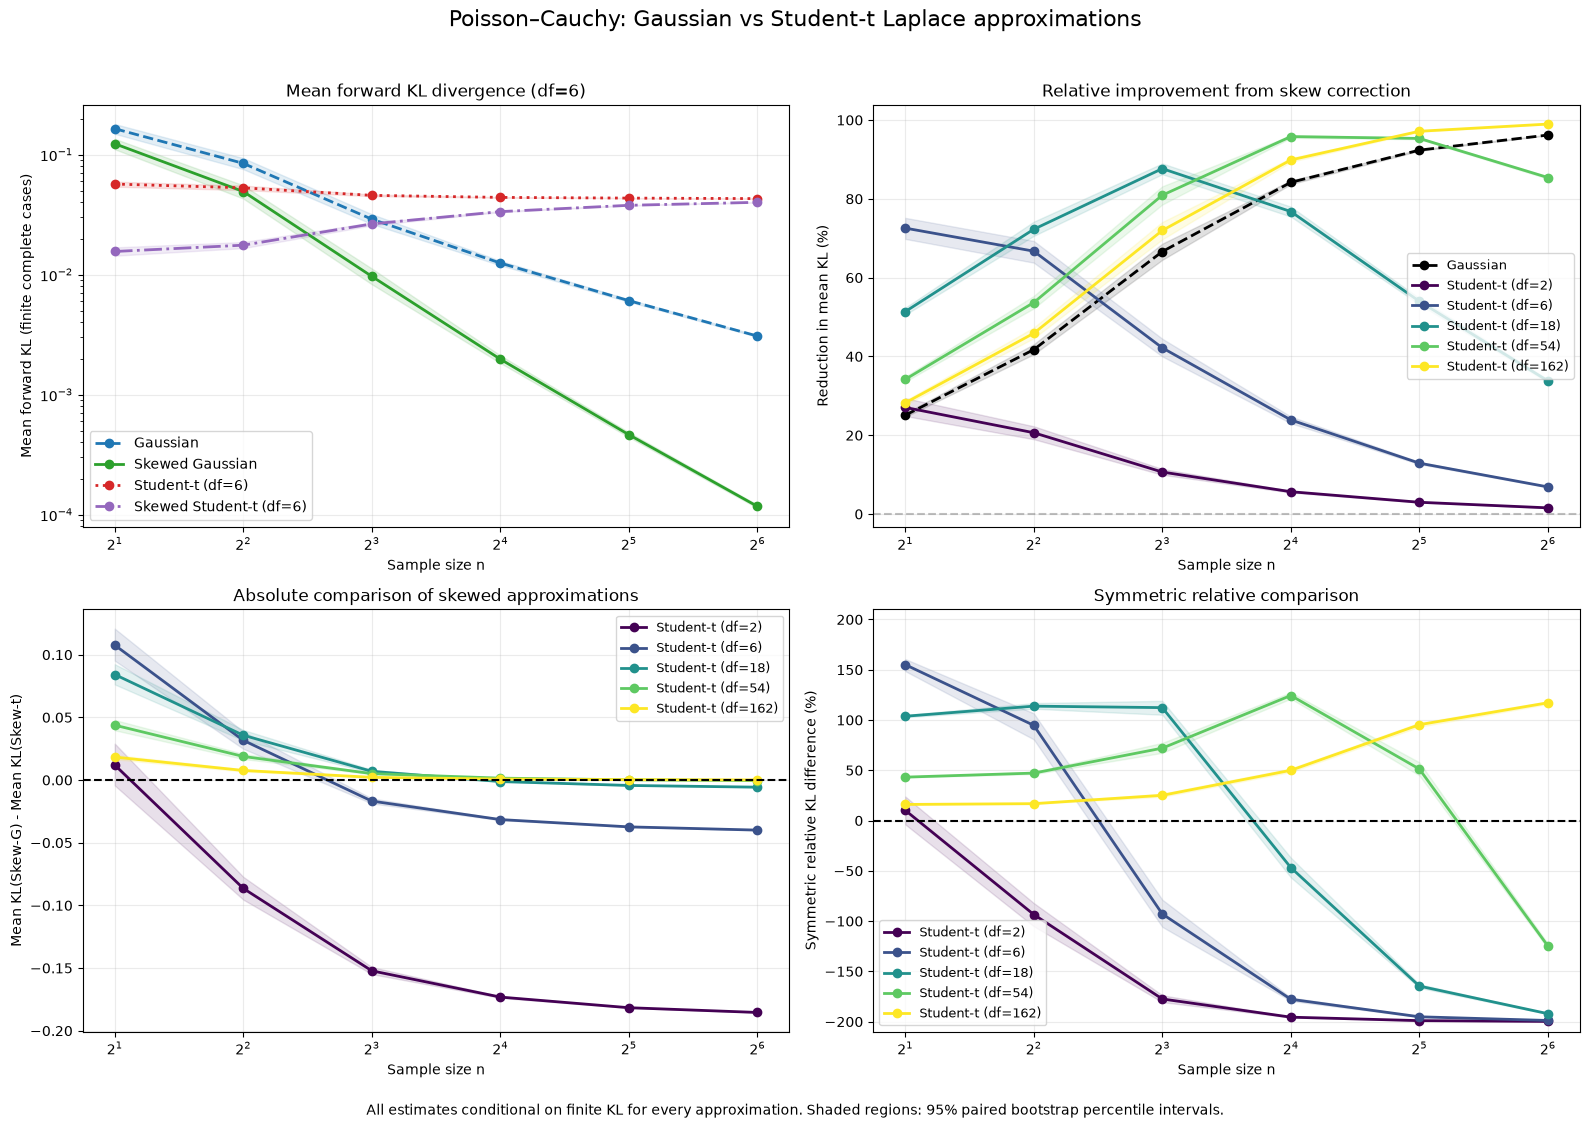


MODEL: Student-t–Cauchy
Student-t degrees of freedom: [2.0, 6.0, 18.0, 54.0, 162.0]

Non-finite KL counts by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                                                                      
2                     0                0                   0                          0
4                     0                0                   0                          0
8                     0                0                   0                          0
16                    0                0                   0                          0
32                    0                0                   0                          0
64                    0                0                   0                          0

Non-finite KL percentages by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                     

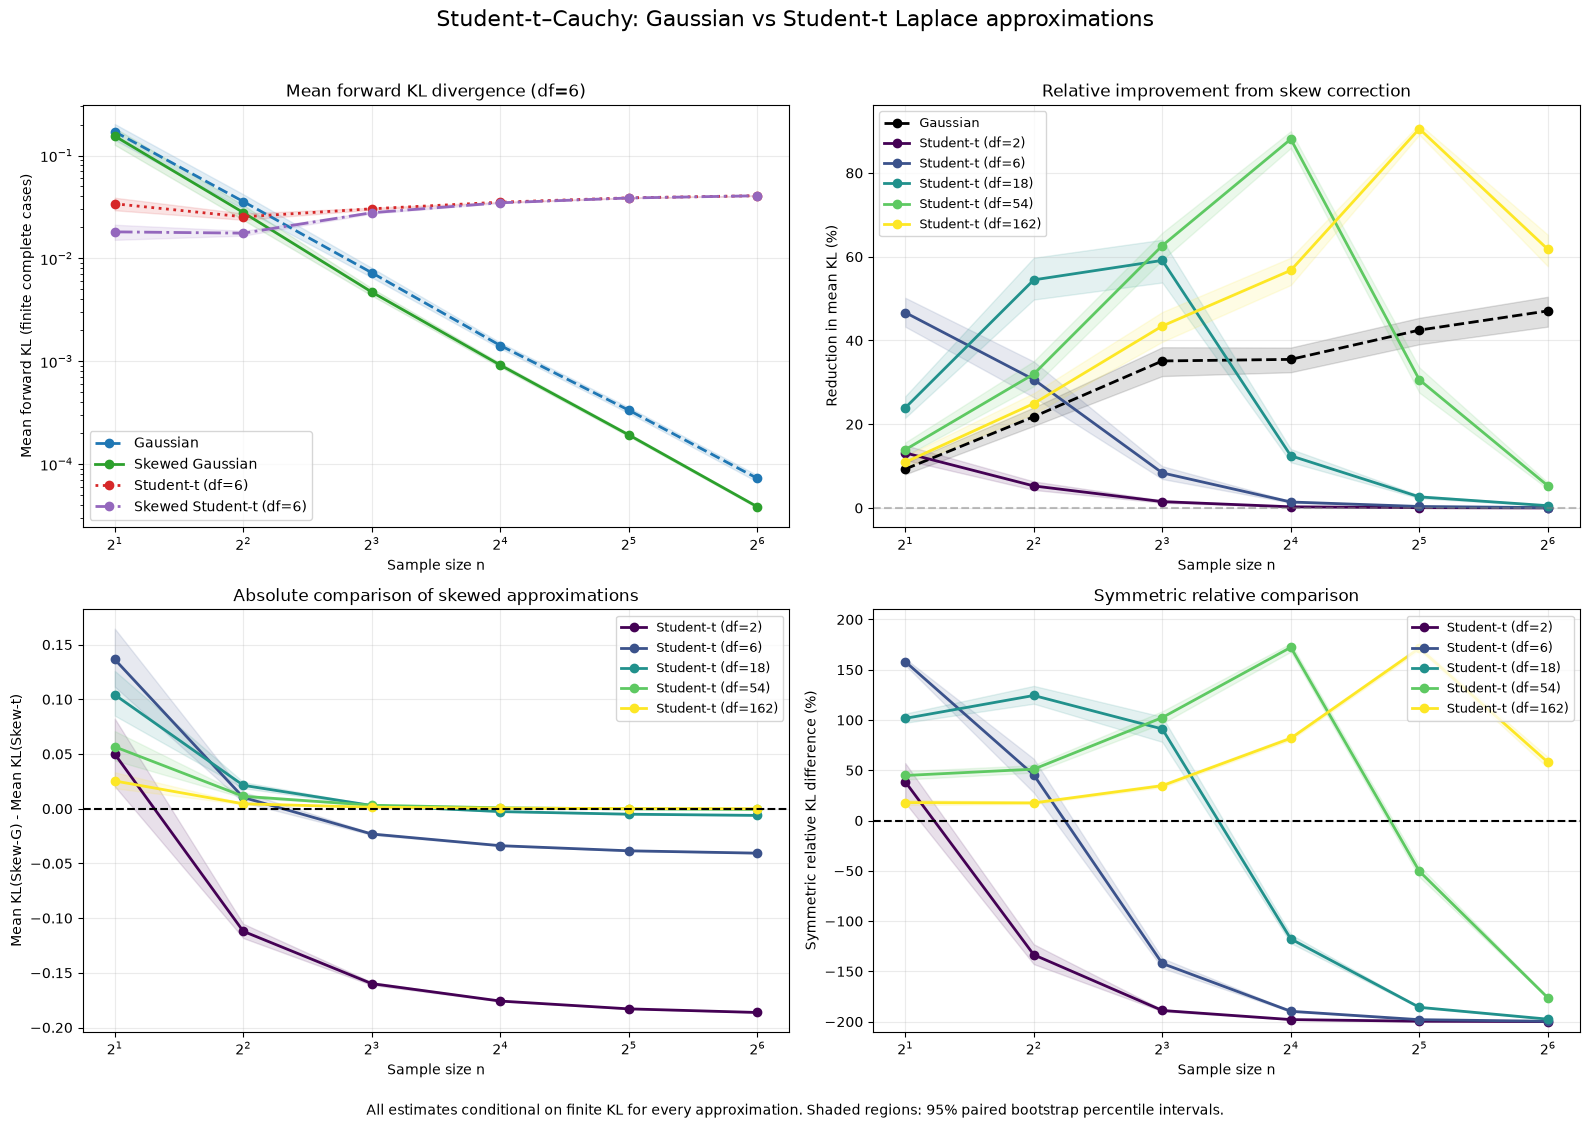


MODEL: Student-t-Cauchy-delayed
Student-t degrees of freedom: [2.0, 6.0, 18.0, 54.0, 162.0]

Non-finite KL counts by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                                                                      
2                     0                0                   0                          0
4                     0                0                   0                          0
8                     0                0                   0                          0
16                    0                0                   0                          0
32                    0                0                   0                          0
64                    0                0                   0                          0
128                   0                0                   0                          0
256                   0                0                   0               

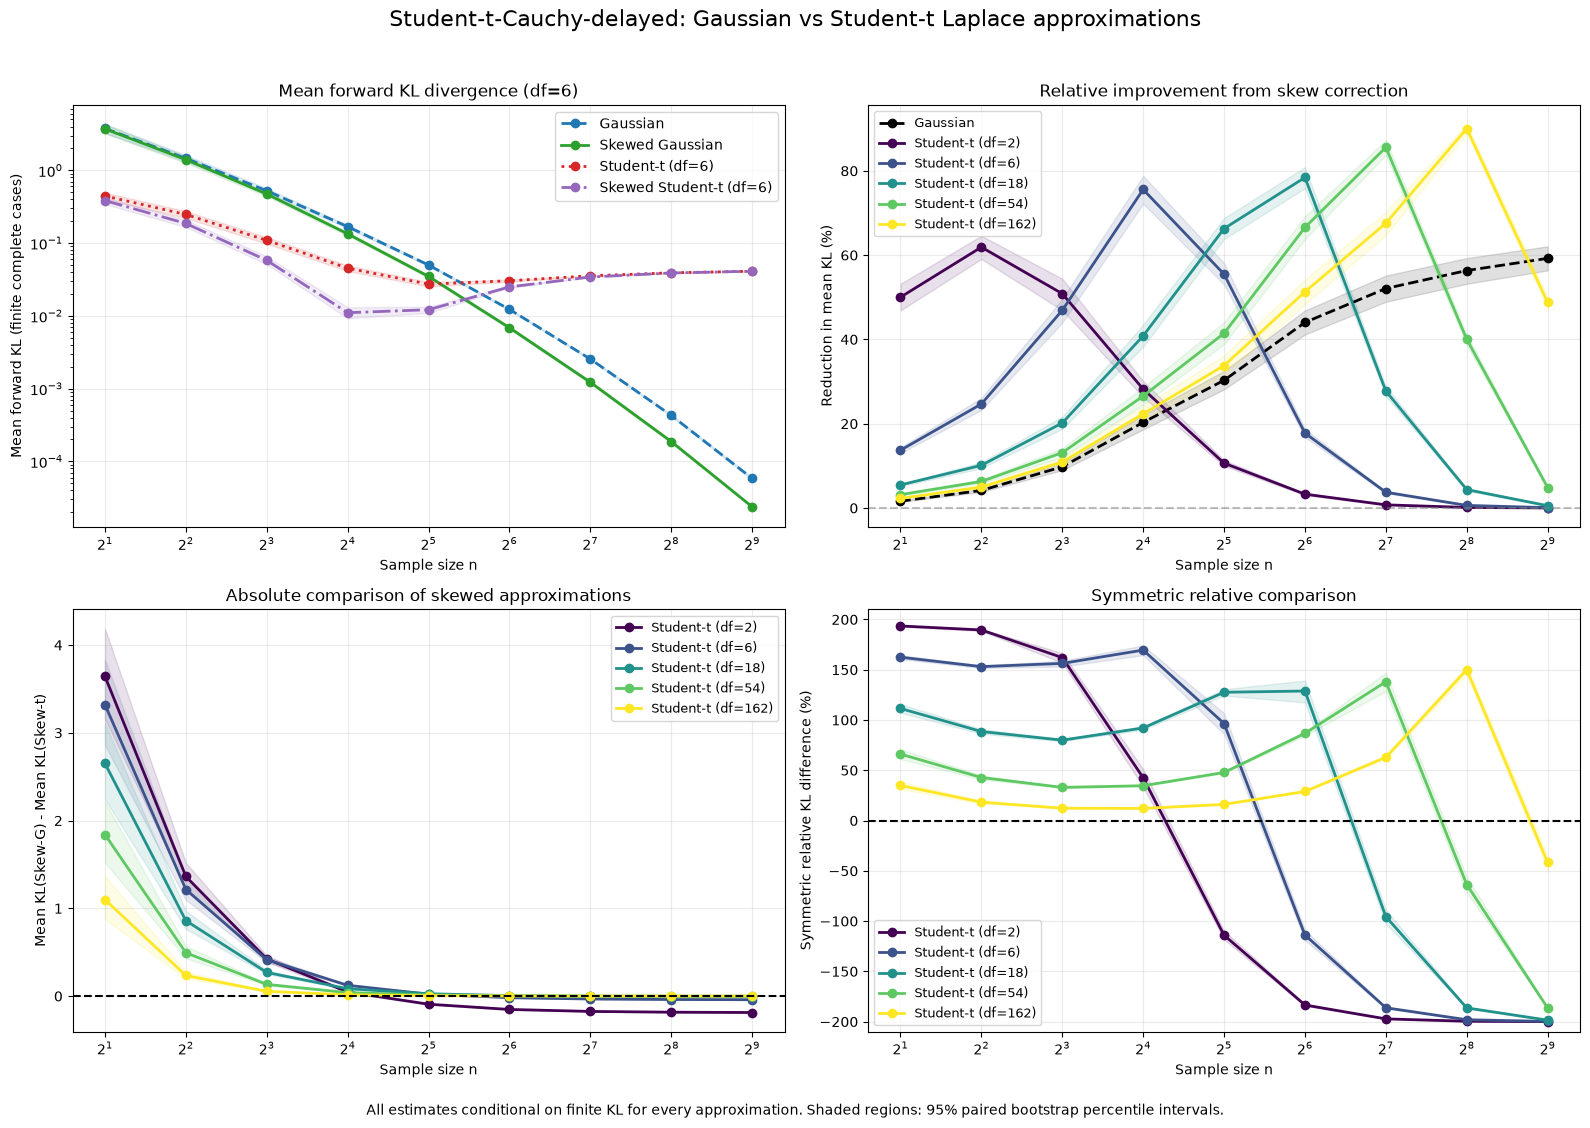


MODEL: Student-t-Cauchy-super delayed
Student-t degrees of freedom: [2.0, 6.0, 18.0, 54.0, 162.0]

Non-finite KL counts by approximation:
approximation  Gaussian  Skewed Gaussian  Student-t (all df)  Skewed Student-t (all df)
n                                                                                      
2                     0                0                   0                          0
4                     0                0                   0                          0
8                     0                0                   0                          0
16                    0                0                   0                          0
32                    0                0                   0                          0
64                    0                0                   0                          0
128                   0                0                   0                          0
256                   0                0                   0         

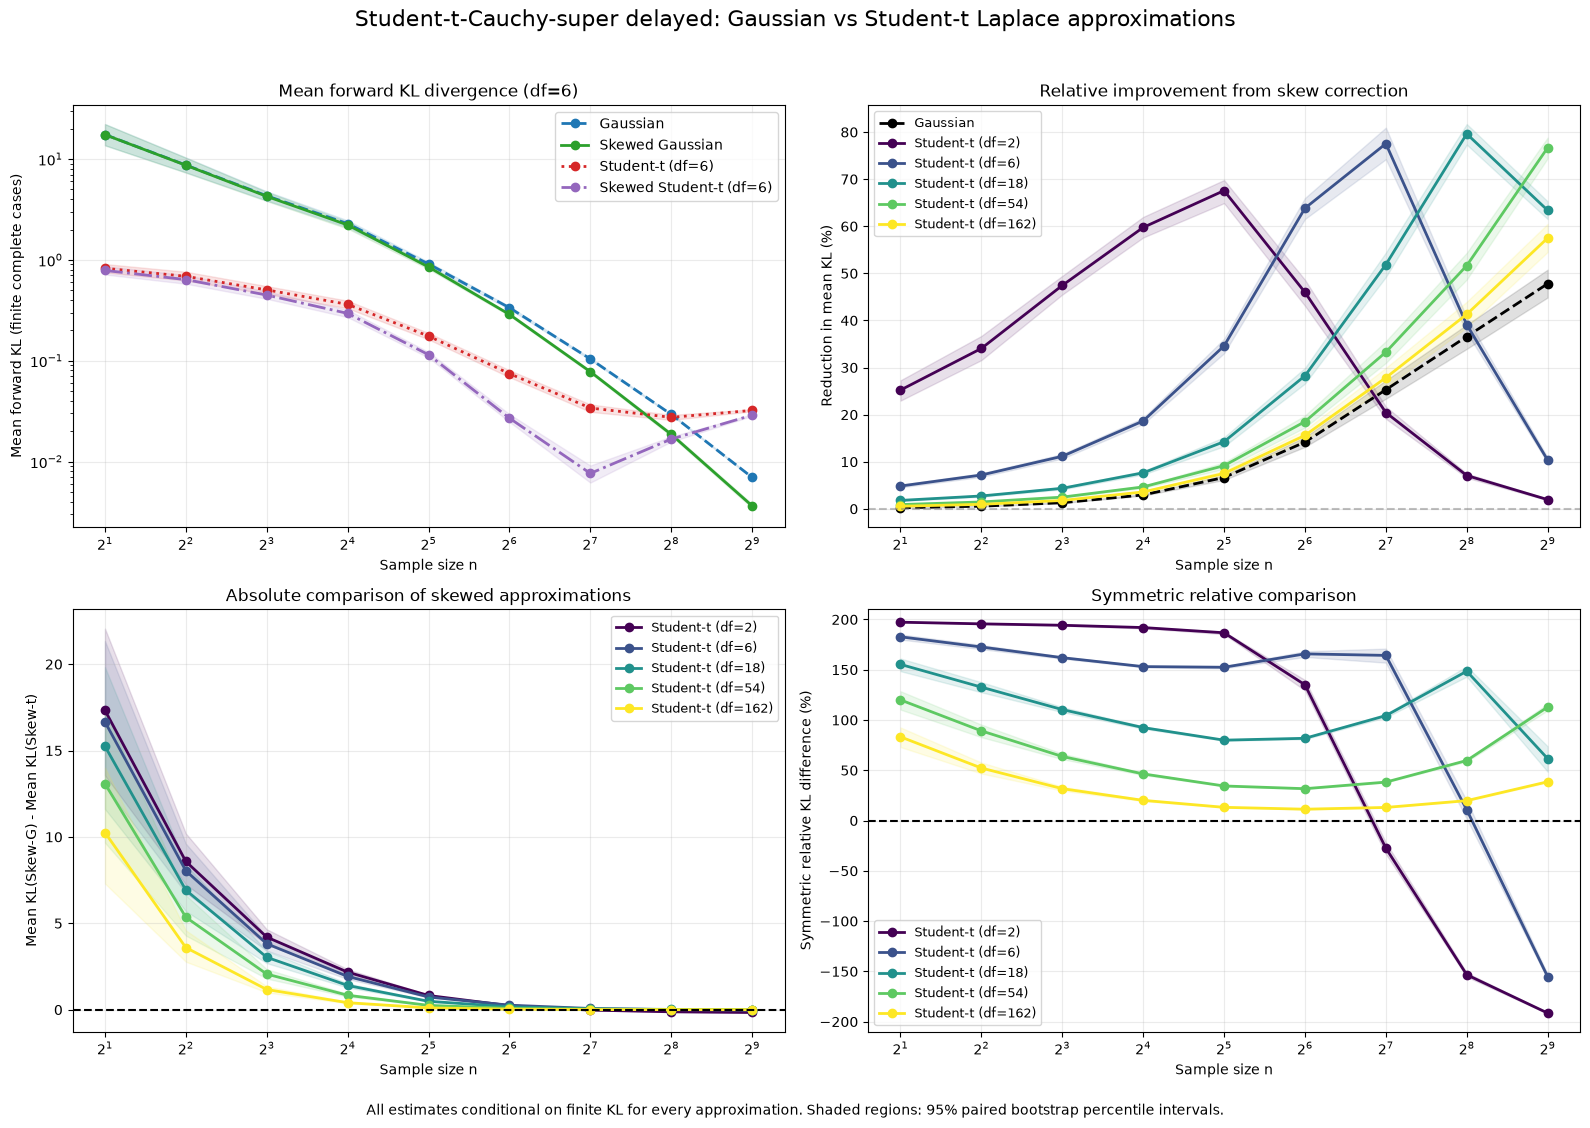

In [24]:

datasets = {
    "Poisson–Cauchy": "simulations_laplace_poisson",
    "Student-t–Cauchy": "simulations_laplace_tstudent", 
    "Student-t-Cauchy-delayed": "simulations_laplace_tstudent_scale4",
    "Student-t-Cauchy-super delayed": "simulations_laplace_tstudent_scale10"

}

for model_name, filename in datasets.items():

    print(f"\n{'=' * 60}")
    print(f"MODEL: {model_name}")
    print(f"{'=' * 60}")

    # ============================================================
    # 1. LOAD AND PREPARE DATA
    # ============================================================

    df = pd.read_csv(filename)

    df["family"] = df["family"].str.strip().str.lower()
    df["kl"] = pd.to_numeric(df["kl"], errors="coerce")
    df["df"] = pd.to_numeric(df["df"], errors="coerce")

    if df["skewed"].dtype != bool:
        df["skewed"] = (
            df["skewed"].astype(str).str.strip().str.lower()
            .map({"true": True, "false": False})
        )

    if df["skewed"].isna().any():
        raise ValueError("Invalid values in the skewed column.")

    # Identify all Student-t degrees of freedom
    vs = sorted(
        df.loc[df["family"] == "student_t", "df"]
        .dropna()
        .unique()
        .tolist()
    )

    reference_v = 6

    if reference_v not in vs:
        raise ValueError("Student-t with df=6 is missing.")

    print("Student-t degrees of freedom:", vs)


    # ============================================================
    # 2. BUILD PAIRED DATAFRAME
    # ============================================================

    # Unique identifier for every approximation
    def method_label(row):
        if row["family"] == "gaussian":
            return "Skewed Gaussian" if row["skewed"] else "Gaussian"

        v = int(row["df"])
        return f"Skewed Student-t ({v})" if row["skewed"] else f"Student-t ({v})"


    df["method"] = df.apply(method_label, axis=1)

    method_names = ["Gaussian", "Skewed Gaussian"]

    for v in vs:
        method_names.extend([
            f"Student-t ({int(v)})",
            f"Skewed Student-t ({int(v)})"
        ])

    keys = ["n", "replicate", "method"]

    if df.duplicated(keys).any():
        raise ValueError("Duplicate simulation results detected.")

    # One row per simulated dataset, 12 KL values per row
    wide = df.pivot(
        index=["n", "replicate"],
        columns="method",
        values="kl"
    )

    # Ensure all expected approximations are present
    missing_methods = set(method_names) - set(wide.columns)

    if missing_methods:
        raise ValueError(f"Missing approximations: {missing_methods}")

    wide = wide[method_names]


    # ============================================================
    # 3. NON-FINITE KL DIAGNOSTICS
    # ============================================================

    # Combine all Student-t degrees of freedom in diagnostics
    diagnostic_groups = {
        "Gaussian": ["Gaussian"],
        "Skewed Gaussian": ["Skewed Gaussian"],
        "Student-t (all df)": [
            f"Student-t ({int(v)})" for v in vs
        ],
        "Skewed Student-t (all df)": [
            f"Skewed Student-t ({int(v)})" for v in vs
        ]
    }

    diagnostic_rows = []

    for n, group in wide.groupby(level="n"):

        for label, columns in diagnostic_groups.items():

            values = group[columns].to_numpy()

            n_nonfinite = (~np.isfinite(values)).sum()
            n_total = values.size

            diagnostic_rows.append({
                "n": n,
                "approximation": label,
                "nonfinite": n_nonfinite,
                "total": n_total,
                "percentage": 100 * n_nonfinite / n_total
            })

    diagnostics = pd.DataFrame(diagnostic_rows)

    missing_counts = diagnostics.pivot(
        index="n",
        columns="approximation",
        values="nonfinite"
    )

    missing_pct = diagnostics.pivot(
        index="n",
        columns="approximation",
        values="percentage"
    )

    missing_counts = missing_counts[
        list(diagnostic_groups)
    ]

    missing_pct = missing_pct[
        list(diagnostic_groups)
    ]

    print("\nNon-finite KL counts by approximation:")
    print(missing_counts.to_string())

    print("\nNon-finite KL percentages by approximation:")
    print(missing_pct.round(2).to_string())


    # ============================================================
    # 4. COMPLETE-CASE FILTERING
    # ============================================================

    # A replicate is retained ONLY if all approximations
    # have finite KL values (all df, plain and skewed).
    finite_mask = np.isfinite(wide.to_numpy()).all(axis=1)

    paired = wide.loc[finite_mask].copy()

    n_total = wide.groupby(level="n").size()
    n_retained = paired.groupby(level="n").size()

    retention = pd.DataFrame({
        "total": n_total,
        "retained": n_retained
    }).fillna(0).astype(int)

    retention["excluded"] = (
        retention["total"] - retention["retained"]
    )

    retention["excluded_pct"] = (
        100 * retention["excluded"] / retention["total"]
    )

    print("\nComplete-case filtering:")
    print(retention.to_string())

    if paired.empty:
        raise ValueError("No complete finite replicates available.")


    # ============================================================
    # 5. DEFINE STATISTICS
    # ============================================================

    # Input: matrix of mean KL values, shape (B, K)
    # Output: matrix of statistics, shape (B, P)

    def calculate_statistics(means):

        # Lookup column positions
        idx = {name: i for i, name in enumerate(method_names)}

        G = means[:, idx["Gaussian"]]
        SG = means[:, idx["Skewed Gaussian"]]

        output = {}

        # Mean KL for reference approximations (df=6)
        for name in [
            "Gaussian",
            "Skewed Gaussian",
            "Student-t (6)",
            "Skewed Student-t (6)"
        ]:
            output[name] = means[:, idx[name]]

        # Gaussian relative improvement from skew correction
        output["gain_gaussian"] = 100 * (1 - SG / G)

        # Statistics for every Student-t df
        for v in vs:

            v = int(v)

            T = means[:, idx[f"Student-t ({v})"]]
            ST = means[:, idx[f"Skewed Student-t ({v})"]]

            # Panel 2: skew correction improvement
            output[f"gain_t_{v}"] = 100 * (1 - ST / T)

            # Panel 3: absolute difference
            output[f"absolute_{v}"] = SG - ST

            # Panel 4: symmetric relative difference
            output[f"symmetric_{v}"] = (
                200 * (SG - ST) / (SG + ST)
            )

        return output


    # ============================================================
    # 6. PAIRED BOOTSTRAP
    # ============================================================

    rng_bootstrap = np.random.default_rng(2026)

    n_bootstrap = 2000
    alpha = 0.025

    records = []

    for n, group in paired.groupby(level="n"):

        values = group.to_numpy(dtype=float)
        R = len(values)

        # Point estimates
        means = values.mean(axis=0, keepdims=True)

        if np.any(means <= 0):
            raise ValueError(
                f"Nonpositive mean KL at n={n}."
            )

        point_stats = calculate_statistics(means)

        # Resample complete paired rows
        indices = rng_bootstrap.integers(
            low=0,
            high=R,
            size=(n_bootstrap, R)
        )

        bootstrap_values = values[indices]
        bootstrap_means = bootstrap_values.mean(axis=1)

        if np.any(bootstrap_means <= 0):
            raise ValueError(
                f"Nonpositive bootstrap mean KL at n={n}."
            )

        bootstrap_stats = calculate_statistics(bootstrap_means)

        row = {
            "n": n,
            "n_replicates": R
        }

        for name in point_stats:

            row[name] = point_stats[name][0]

            row[f"{name}_lower"] = np.quantile(
                bootstrap_stats[name], alpha
            )

            row[f"{name}_upper"] = np.quantile(
                bootstrap_stats[name], 1 - alpha
            )

        records.append(row)

    summary = pd.DataFrame(records).sort_values("n")


    # ============================================================
    # 7. SUMMARY STATISTICS — STUDENT-T DF=6 ONLY
    # ============================================================

    summary_columns = [
        "n",
        "n_replicates",
        "Gaussian",
        "Skewed Gaussian",
        "Student-t (6)",
        "Skewed Student-t (6)",
        "gain_gaussian",
        "gain_t_6",
        "absolute_6",
        "symmetric_6"
    ]

    print("\nSummary statistics (Student-t df=6):")
    print(
        summary[summary_columns]
        .round(5)
        .to_string(index=False)
    )


    # ============================================================
    # 8. PLOT SETTINGS
    # ============================================================

    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 11)
    )

    x = summary["n"].to_numpy()

    # Student-t colors: shades from the same palette
    cmap = plt.get_cmap("viridis")

    t_colors = {
        int(v): cmap(i / max(1, len(vs) - 1))
        for i, v in enumerate(vs)
    }

    gaussian_color = "black"


    # Helper: plot a curve and its bootstrap interval
    def plot_with_ci(ax, key, label, color, linestyle="-"):

        y = summary[key].to_numpy(dtype=float)
        lower = summary[f"{key}_lower"].to_numpy(dtype=float)
        upper = summary[f"{key}_upper"].to_numpy(dtype=float)

        ax.plot(
            x, y,
            marker="o",
            linewidth=2,
            color=color,
            linestyle=linestyle,
            label=label
        )

        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.12
        )


    # ============================================================
    # PANEL 1 — MEAN FORWARD KL (DF=6 ONLY)
    # ============================================================

    ax = axes[0, 0]

    reference_methods = [
        ("Gaussian", "Gaussian", "tab:blue", "--"),
        ("Skewed Gaussian", "Skewed Gaussian", "tab:green", "-"),
        ("Student-t (6)", "Student-t (df=6)", "tab:red", ":"),
        ("Skewed Student-t (6)", "Skewed Student-t (df=6)", "tab:purple", "-.")
    ]

    for key, label, color, linestyle in reference_methods:
        plot_with_ci(ax, key, label, color, linestyle)

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")

    ax.set_title("Mean forward KL divergence (df=6)")
    ax.set_xlabel("Sample size n")
    ax.set_ylabel("Mean forward KL (finite complete cases)")
    ax.legend()
    ax.grid(alpha=0.25)


    # ============================================================
    # PANEL 2 — RELATIVE IMPROVEMENT FROM SKEW CORRECTION
    # ============================================================

    ax = axes[0, 1]

    plot_with_ci(
        ax,
        "gain_gaussian",
        "Gaussian",
        gaussian_color,
        "--"
    )

    for v in vs:
        v = int(v)

        plot_with_ci(
            ax,
            f"gain_t_{v}",
            f"Student-t (df={v})",
            t_colors[v]
        )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)

    ax.set_xscale("log", base=2)
    ax.set_title("Relative improvement from skew correction")
    ax.set_xlabel("Sample size n")
    ax.set_ylabel("Reduction in mean KL (%)")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)


    # ============================================================
    # PANEL 3 — ABSOLUTE DIFFERENCE, GAUSSIAN VS EACH STUDENT-T
    # ============================================================

    ax = axes[1, 0]

    for v in vs:
        v = int(v)

        plot_with_ci(
            ax,
            f"absolute_{v}",
            f"Student-t (df={v})",
            t_colors[v]
        )

    ax.axhline(0, color="black", linestyle="--")

    ax.set_xscale("log", base=2)
    ax.set_title("Absolute comparison of skewed approximations")
    ax.set_xlabel("Sample size n")
    ax.set_ylabel("Mean KL(Skew-G) - Mean KL(Skew-t)")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)


    # ============================================================
    # PANEL 4 — SYMMETRIC RELATIVE DIFFERENCE
    # ============================================================

    ax = axes[1, 1]

    for v in vs:
        v = int(v)

        plot_with_ci(
            ax,
            f"symmetric_{v}",
            f"Student-t (df={v})",
            t_colors[v]
        )

    ax.axhline(0, color="black", linestyle="--")

    ax.set_xscale("log", base=2)
    ax.set_ylim(-210, 210)

    ax.set_title("Symmetric relative comparison")
    ax.set_xlabel("Sample size n")
    ax.set_ylabel("Symmetric relative KL difference (%)")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)


    # ============================================================
    # FINAL FORMATTING
    # ============================================================

    fig.suptitle(
        f"{model_name}: Gaussian vs Student-t Laplace approximations",
        fontsize=16,
        y=1.01
    )

    fig.text(
        0.5,
        0.005,
        "All estimates conditional on finite KL for every approximation. "
        "Shaded regions: 95% paired bootstrap percentile intervals.",
        ha="center",
        fontsize=10
    )

    plt.tight_layout(rect=[0, 0.025, 1, 0.99])
    plt.show()
